In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge,Lasso,ElasticNet

DATA_PATH = "../dataset/house_price_dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:\n", df.isna().sum())

numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns

for col in numeric_cols:
    if col not in ["House_ID", "Price"]:
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

Dataset shape: (15025, 18)


,House_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated,Price
0,3975,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no,309277.0
1,12325,2646.2,2.0,5.0,2.0,2005,riverside,NaN,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y,563512.0
2,7202,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,NaN,Yes,no,495806.0
3,8355,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes,240776.0
4,12742,3227.0,3.0,5.0,2.0,1995,NaN,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes,413975.0



Missing values:
 House_ID                         0
Area_sqft                      603
Bedrooms                       450
Bathrooms                      300
Floors                           0
Year_Built                       0
Location                       751
Furnishing_Status              901
Parking_Available              603
Garage_Count                   300
Lot_Size_sqft                  450
Condition                      450
Distance_to_City_Center_km     300
Crime_Rate_Index                 0
School_Rating                 1051
Has_Pool                         0
Renovated                        0
Price                            0
dtype: int64
House_ID                      0
Area_sqft                     0
Bedrooms                      0
Bathrooms                     0
Floors                        0
Year_Built                    0
Location                      0
Furnishing_Status             0
Parking_Available             0
Garage_Count                  0
Lot_Size_sqft      

In [2]:
price_median = df["Price"].median()

df["Price_Class"] = (df["Price"] >= price_median).astype(int)

X = df.drop(columns=["Price", "Price_Class", "House_ID"])
y = df["Price_Class"]

print("Median House Price:", price_median)
print("\nClass Distribution:")
print(y.value_counts())

Median House Price: 359454.0

Class Distribution:
Price_Class
1    7513
0    7512
Name: count, dtype: int64


In [3]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Garage_Count', 'Lot_Size_sqft', 'Distance_to_City_Center_km', 'Crime_Rate_Index', 'School_Rating']
Categorical Features: ['Location', 'Furnishing_Status', 'Parking_Available', 'Condition', 'Has_Pool', 'Renovated']


In [4]:
numeric_transformer = Pipeline([
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (12020, 16)
Testing Data: (3005, 16)


In [6]:
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [7]:
y_pred = dt_model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
[0 0 0 1 1 0 0 0 1 1 1 0 1 0 1 1 0 1 1 1]


In [8]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Below Median", "At/Above Median"]
))

Accuracy: 0.8176372712146422

Classification Report:
                 precision    recall  f1-score   support

   Below Median       0.87      0.75      0.80      1502
At/Above Median       0.78      0.89      0.83      1503

       accuracy                           0.82      3005
      macro avg       0.82      0.82      0.82      3005
   weighted avg       0.82      0.82      0.82      3005



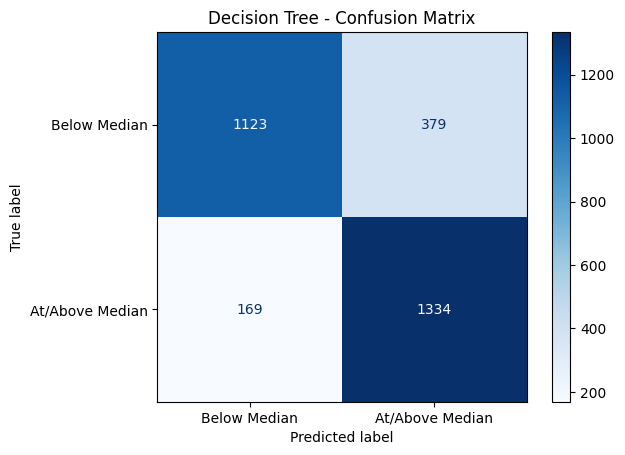

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Below Median", "At/Above Median"],
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

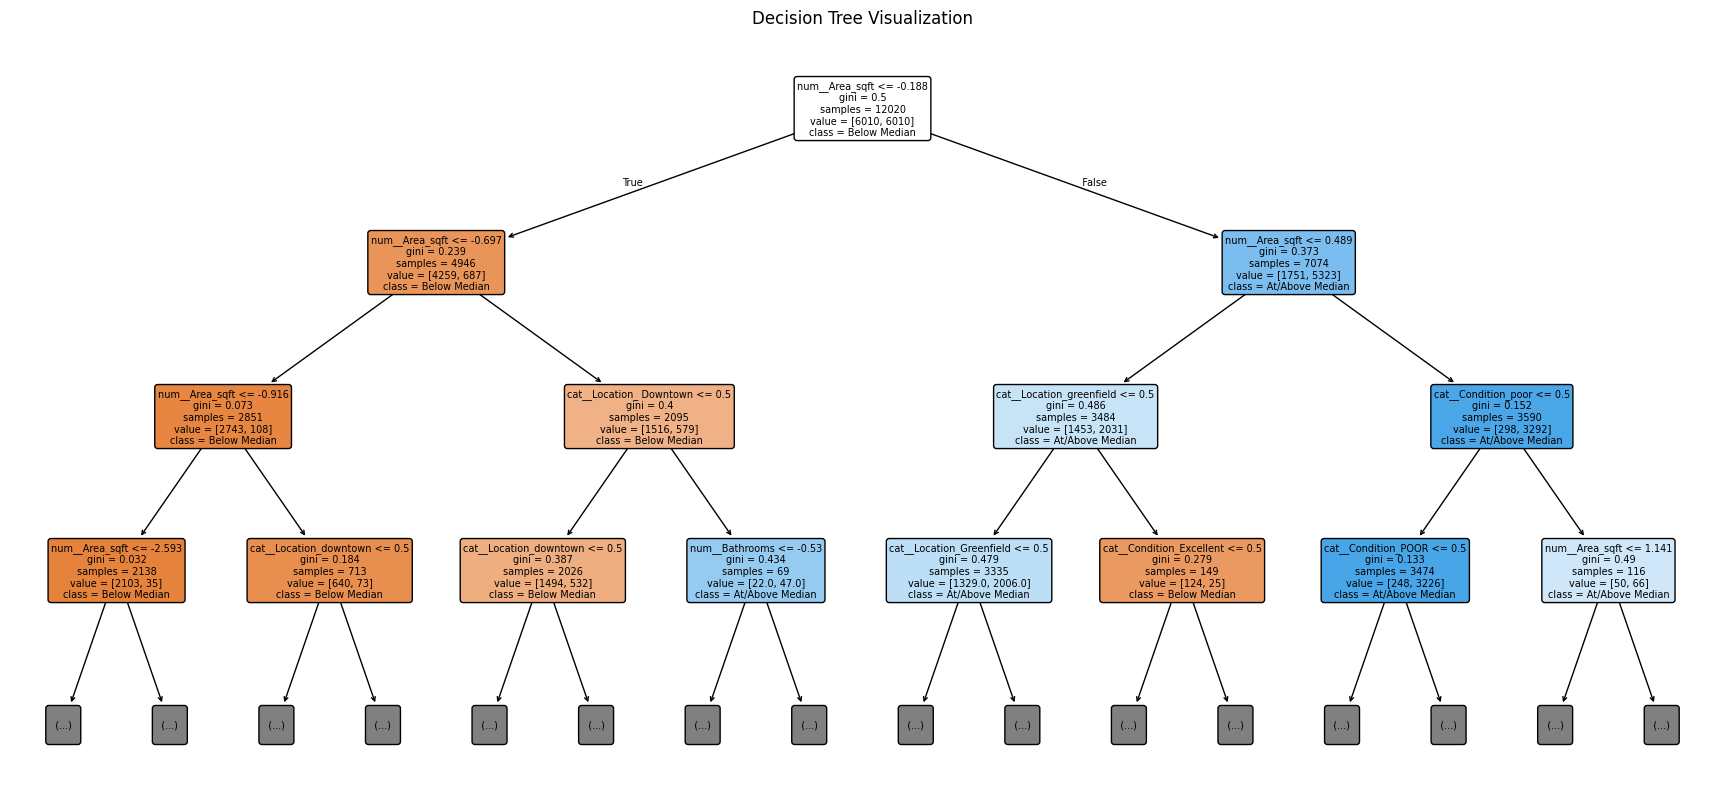

In [10]:
feature_names = dt_model.named_steps["preprocessor"].get_feature_names_out()

plt.figure(figsize=(22, 10))

plot_tree(
    dt_model.named_steps["classifier"],
    feature_names=feature_names,
    class_names=["Below Median", "At/Above Median"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=7
)

plt.title("Decision Tree Visualization")
plt.show()

In [11]:
sample = X_test.iloc[[0]]

prediction = dt_model.predict(sample)[0]

if prediction == 1:
    print("Predicted Class: At or Above Median Price")
else:
    print("Predicted Class: Below Median Price")

Predicted Class: Below Median Price
